In [ ]:
import pandas as pd

gen_df = pd.read_csv("combined.csv")
spark_df = pd.read_csv("alice_dracula_sparknotes_chapters.csv")

spark_df = spark_df.rename(columns={"book": "book_title"})


gen_df["chapter_num"] = pd.to_numeric(gen_df["chapter_num"], errors="coerce")
spark_df["chapter_num"] = pd.to_numeric(spark_df["chapter_num"], errors="coerce")

gen_df = gen_df.dropna(subset=["chapter_num"])
spark_df = spark_df.dropna(subset=["chapter_num"])

gen_df["chapter_num"] = gen_df["chapter_num"].astype(int)
spark_df["chapter_num"] = spark_df["chapter_num"].astype(int)

spark_df = spark_df[spark_df["book_title"].isin(gen_df["book_title"].unique())].copy()


human_df = spark_df[["book_title", "chapter_num", "summary_text", "summary_length"]].copy()
human_df = human_df.rename(columns={"summary_text": "human_summary"})


merged = pd.merge(
    gen_df,
    human_df,
    on=["book_title", "chapter_num"],
    how="inner",
)

print(merged[["book_title", "chapter_num", "chapter_summary", "human_summary"]].head())
merged.to_csv("merged_summaries.csv", index=False)
print("Saved merged_summaries.csv with columns:")
print(merged.columns.tolist())


            book_title  chapter_num  \
0  Alice in Wonderland            1   
1  Alice in Wonderland            2   
2  Alice in Wonderland            3   
3  Alice in Wonderland            4   
4  Alice in Wonderland            5   

                                     chapter_summary  \
0  CHAPTER I: Down the Rabbit-Hole\nAlice, feelin...   
1  CHAPTER II: The Pool of Tears\nAlice grows eno...   
2  CHAPTER III:\nAfter swimming in the pool of te...   
3  CHAPTER IV: The Rabbit Sends in a Little Bill\...   
4  CHAPTER V: Advice from a Caterpillar\nAlice en...   

                                       human_summary  
0  Alice sits drowsily by a riverbank, bored by t...  
1  After finishing the cake that says "EAT ME," A...  
2  Alice and the group of animals land on the ban...  
3  The White Rabbit approaches Alice, looking for...  
4  Alice comes across a Caterpillar that is resti...  
Saved merged_summaries.csv with columns:
['chapter_summary', 'book_title', 'source', 'chapter_num'

In [ ]:
!pip install -q evaluate rouge-score bert-score

import pandas as pd
import numpy as np
import evaluate


merged = pd.read_csv("merged_summaries.csv")
eval_df = merged.dropna(subset=["chapter_summary", "human_summary"]).copy()
eval_df = eval_df[
    (eval_df["chapter_summary"].str.strip() != "") &
    (eval_df["human_summary"].str.strip() != "")
]

preds = eval_df["chapter_summary"].astype(str).tolist()
refs  = eval_df["human_summary"].astype(str).tolist()

print(f"Number of evaluated pairs: {len(preds)}")

# 4. ROUGE-L per row
rouge_metric = evaluate.load("rouge")

def compute_rouge_l(pred, ref):
    res = rouge_metric.compute(
        predictions=[pred],
        references=[ref],
        rouge_types=["rougeL"],
        use_stemmer=True,
    )

    return res["rougeL"]

eval_df["rougeL"] = [
    compute_rouge_l(p, r) for p, r in zip(preds, refs)
]

# 5. BERTScore F1 per row (computed in one shot)
bertscore_metric = evaluate.load("bertscore")
bertscore_res = bertscore_metric.compute(
    predictions=preds,
    references=refs,
    lang="en",
    # model_type parameter is optional; default is fine for now
)

eval_df["bertscore_f1"] = bertscore_res["f1"]

# 6. Copy the scores back onto the main merged df (align by index)
merged.loc[eval_df.index, "rougeL"] = eval_df["rougeL"]
merged.loc[eval_df.index, "bertscore_f1"] = eval_df["bertscore_f1"]

# 7. Quick peek
print(
    merged[["book_title", "chapter_num", "rougeL", "bertscore_f1"]]
    .head()
)

# 8. Save scored file
merged.to_csv("merged_summaries_scored.csv", index=False)
print("Saved merged_summaries_scored.csv")



Number of evaluated pairs: 39


model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


            book_title  chapter_num    rougeL  bertscore_f1
0  Alice in Wonderland            1  0.109005      0.833113
1  Alice in Wonderland            2  0.100000      0.833775
2  Alice in Wonderland            3  0.195122      0.852941
3  Alice in Wonderland            4  0.162662      0.840044
4  Alice in Wonderland            5  0.180412      0.856557
Saved merged_summaries_scored.csv


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plot_df = merged.dropna(subset=["rougeL", "bertscore_f1"]).copy()

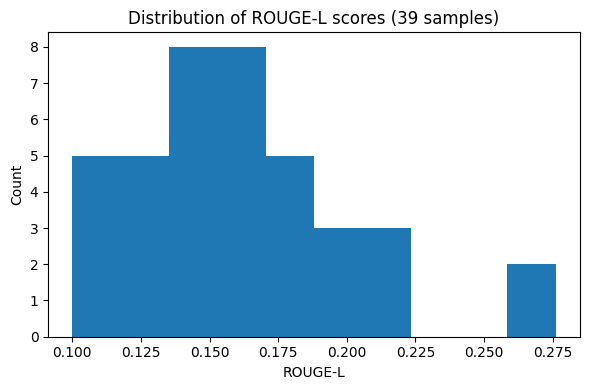

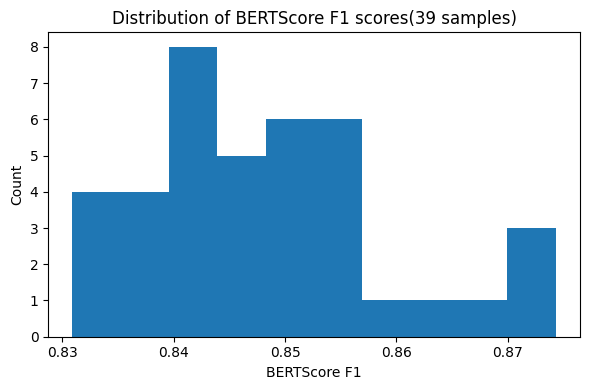

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(plot_df["rougeL"], bins=10)
plt.xlabel("ROUGE-L")
plt.ylabel("Count")
plt.title("Distribution of ROUGE-L scores (39 samples)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
plt.hist(plot_df["bertscore_f1"], bins=10)
plt.xlabel("BERTScore F1")
plt.ylabel("Count")
plt.title("Distribution of BERTScore F1 scores(39 samples)")
plt.tight_layout()
plt.show()


In [ ]:
book_stats = (
    plot_df
    .groupby("book_title")[["rougeL", "bertscore_f1"]]
    .mean()
    .reset_index()
)
print(book_stats)


            book_title    rougeL  bertscore_f1
0  Alice in Wonderland  0.152105      0.842275
1              Dracula  0.166465      0.850974


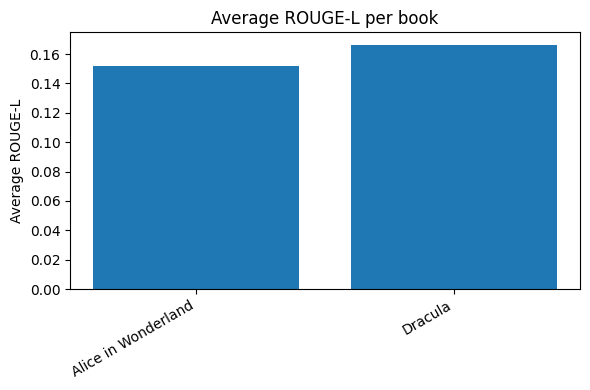

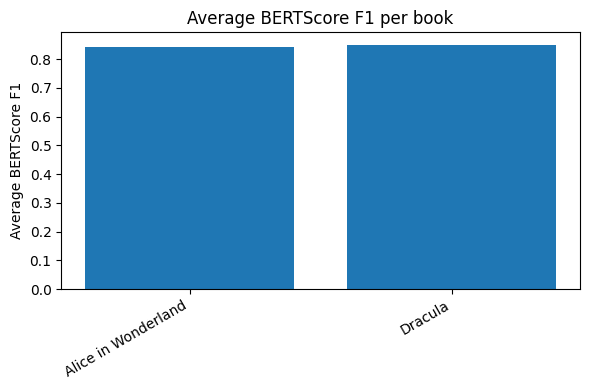

In [ ]:
# Average ROUGE-L per book
plt.figure(figsize=(6,4))
plt.bar(book_stats["book_title"], book_stats["rougeL"])
plt.ylabel("Average ROUGE-L")
plt.title("Average ROUGE-L per book")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Average BERTScore F1 per book
plt.figure(figsize=(6,4))
plt.bar(book_stats["book_title"], book_stats["bertscore_f1"])
plt.ylabel("Average BERTScore F1")
plt.title("Average BERTScore F1 per book")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
